# Avance 2 · Modelado, visualización y prototipo de dashboard
## Sistema Web con Inteligencia de Negocios para el Diagnóstico de QoS y Cobertura WiFi en la Red Hospitalaria UniFi

| | |
|---|---|
| **Integrantes** | Martínez Pérez José Armando · Hernández Valencia María de Jesús |
| **Docente** | Mtra. Sandra Lucía de la Fuente Bermúdez |
| **Datos** | `Dataset/Analisis_Red_Hospital.xlsx` (hoja *Datos*, 1,000 sesiones) |
| **Reproducibilidad** | Ejecutar con *Reiniciar y ejecutar todo*. Semilla fija `2026`. Las figuras se guardan en `figuras/`. |

## 0. Configuración

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 2026
np.random.seed(SEMILLA)

# Paleta institucional (azul / naranja: distinguibles con daltonismo) + gris neutro
AZUL, NARANJA, GRIS, AZUL_SUAVE = "#1B396A", "#E8852A", "#8C8C8C", "#DCE6F2"
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlelocation": "left"})

# Rutas relativas al repositorio (el notebook vive en Protocolo/Avance 2/)
RAIZ = Path.cwd()
while not (RAIZ / "Dataset").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
ARCHIVO = RAIZ / "Dataset" / "Analisis_Red_Hospital.xlsx"
FIG = Path.cwd() / "figuras"
FIG.mkdir(exist_ok=True)
print("Dataset:", ARCHIVO.relative_to(RAIZ))

Dataset: Dataset/Analisis_Red_Hospital.xlsx


In [2]:
crudo = pd.read_excel(ARCHIVO, sheet_name="Datos")
nombres = {
    "ID": "id_sesion", "Nombre del cliente": "cliente", "Dirección MAC": "mac", "Dirección IP": "ip",
    "Fabricante": "fabricante", "Tipo de dispositivo": "tipo_dispositivo", "Sistema operativo": "so",
    "Rol del usuario": "rol", "Área del hospital": "area", "Piso": "piso", "Red (VLAN)": "red",
    "ID VLAN": "id_vlan", "Tipo de conexión": "conexion", "SSID": "ssid", "Conectado a (AP/Switch)": "ap_switch",
    "Puerto del switch": "puerto", "Banda WiFi": "banda", "Estándar WiFi": "estandar", "Canal": "canal",
    "Señal (dBm)": "senal_dbm", "Experiencia (%)": "experiencia", "Velocidad TX (Mbps)": "tx_mbps",
    "Velocidad RX (Mbps)": "rx_mbps", "Descarga (GB)": "descarga_gb", "Subida (GB)": "subida_gb",
    "Aplicación principal (DPI)": "aplicacion", "Primera conexión": "primera_conexion",
    "Última conexión": "ultima_conexion", "Tiempo conectado (h)": "horas_conectado", "Estado": "estado",
    "Día de la semana": "dia", "Hora de conexión": "hora",
}
datos = crudo.rename(columns=nombres)
print(f"Registros: {len(datos):,} | Variables: {datos.shape[1]} | Duplicados exactos: {datos.duplicated().sum()}")
print(datos["conexion"].value_counts().to_string())

Registros: 1,000 | Variables: 32 | Duplicados exactos: 0
conexion
WiFi        640
Cableado    360


## 1. Correcciones del Avance 1
Estas celdas recalculan las cifras del Avance 1 que estaban incompletas o no coincidían con el dataset. Cada resultado se cita en la tabla de retroalimentación del reporte.

**C1. Porcentaje de streaming.** El Avance 1 decía "29.33 % de la descarga total (51.25 GB de 174.73 GB)", pero 174.73 GB es solo la descarga de la red Invitados.

In [3]:
# (C1) Porcentaje de streaming: ¿de qué total?
inv = datos[datos["red"] == "Invitados"]
gb_stream_inv = inv.loc[inv["aplicacion"] == "Streaming de video", "descarga_gb"].sum()
gb_inv = inv["descarga_gb"].sum()
gb_total = datos["descarga_gb"].sum()
print(f"Descarga total del hospital: {gb_total:,.2f} GB")
print(f"Descarga en red Invitados:   {gb_inv:,.2f} GB")
print(f"Streaming en Invitados:      {gb_stream_inv:,.2f} GB")
print(f"  -> {gb_stream_inv / gb_inv * 100:.2f} % de la descarga de Invitados")
print(f"  -> {gb_stream_inv / gb_total * 100:.2f} % de la descarga total del hospital")
print("Sesiones de streaming fuera de Invitados:",
      ((datos["aplicacion"] == "Streaming de video") & (datos["red"] != "Invitados")).sum())

Descarga total del hospital: 5,774.77 GB
Descarga en red Invitados:   174.73 GB
Streaming en Invitados:      51.24 GB
  -> 29.33 % de la descarga de Invitados
  -> 0.89 % de la descarga total del hospital
Sesiones de streaming fuera de Invitados: 0


**C2. Experiencia y señal por área.** El Avance 1 atribuía −66.7 dBm a Dirección y reportaba 86.4 % y 87.5 % para Urgencias y UCI; aquí se recalculan.

In [4]:
# (C2) Experiencia por área (todas las sesiones y solo WiFi) y señal por área del Piso 3
exp_area = (datos.groupby("area")
            .agg(sesiones=("experiencia", "size"), exp_media=("experiencia", "mean"),
                 exp_media_wifi=("experiencia", lambda s: s[datos.loc[s.index, "conexion"] == "WiFi"].mean()),
                 senal_media_dbm=("senal_dbm", "mean"))
            .round(1).sort_values("exp_media"))
display(exp_area)
p3 = datos[datos["piso"] == "P3"]
print(f"Piso 3: descarga total {p3['descarga_gb'].sum():,.2f} GB | descarga WiFi {p3.loc[p3['conexion']=='WiFi','descarga_gb'].sum():,.2f} GB")

,sesiones,exp_media,exp_media_wifi,senal_media_dbm
area,,,,
Sistemas,21,73.0,64.1,-65.6
Pediatría,91,73.4,73.0,-60.4
Hospitalización,158,75.9,71.9,-60.1
Quirófanos,71,77.0,68.4,-61.9
Ginecobstetricia,60,78.6,74.1,-60.4
Consulta Externa,81,81.4,76.3,-58.2
UCI,92,81.8,76.9,-56.7
Cafetería,50,83.6,80.4,-56.7
Urgencias,122,84.0,77.5,-56.6


Piso 3: descarga total 648.95 GB | descarga WiFi 105.16 GB


**C3. Atípicos con 1.5 × RIC.** El Avance 1 no reportaba el conteo. Decisión: se conservan, porque son sesiones reales (p. ej., las cámaras de Seguridad suben cientos de GB por diseño).

In [5]:
# (C3) Atípicos con el criterio 1.5 x RIC
def atipicos_ric(x):
    q1, q3 = x.quantile([0.25, 0.75]); ric = q3 - q1
    return int(((x < q1 - 1.5 * ric) | (x > q3 + 1.5 * ric)).sum()), q3 + 1.5 * ric

tabla_atip = pd.DataFrame({v: atipicos_ric(datos[v].dropna()) for v in
                           ["descarga_gb", "subida_gb", "horas_conectado", "experiencia", "senal_dbm"]},
                          index=["n_atipicos", "limite_superior"]).T.round(2)
display(tabla_atip)
print("Subida media por rol (GB):")
display(datos.groupby("rol")["subida_gb"].agg(["count", "mean", "median", "std"]).round(2).sort_values("mean", ascending=False))

,n_atipicos,limite_superior
descarga_gb,128.0,5.21
subida_gb,129.0,1.45
horas_conectado,30.0,132.40
experiencia,0.0,135.00
senal_dbm,6.0,-41.50


Subida media por rol (GB):


,count,mean,median,std
rol,,,,
Seguridad,26,583.15,308.22,625.85
Técnico radiólogo,42,11.63,7.94,9.78
Biomédico / Equipo médico,87,3.73,0.11,11.83
TI,15,1.21,1.15,0.71
Laboratorista,26,1.03,0.77,0.76
Administrativo,123,0.96,0.59,1.04
Farmacéutico,13,0.65,0.45,0.46
Médico,169,0.46,0.25,0.62
Enfermería,201,0.44,0.23,0.78


**C4. Tiempo conectado por área.** La columna que el Avance 1 llamó "sd" era en realidad el coeficiente de variación (%).

In [6]:
# (C4) Tiempo conectado por área: la columna que se reportó como "sd" era el CV (%)
t_area = datos.groupby("area")["horas_conectado"].agg(n="size", media="mean", sd="std")
t_area["cv_pct"] = t_area["sd"] / t_area["media"] * 100
display(t_area.round(2).sort_values("media", ascending=False))

,n,media,sd,cv_pct
area,,,,
Farmacia,26,62.34,35.90,57.59
Laboratorio,38,61.30,41.29,67.36
Imagenología,43,61.08,36.53,59.81
Dirección,48,60.89,49.45,81.20
Administración,42,48.54,45.39,93.52
UCI,92,46.72,46.24,98.98
Recepción,57,38.31,44.01,114.89
Quirófanos,71,37.84,38.89,102.79
Urgencias,122,32.12,34.03,105.95


**C5. Prueba de hipótesis completa** (H0: μ cableado = μ WiFi; H1: μ cableado > μ WiFi; α = 0.05; t de Welch).

In [7]:
# (C5) Prueba de hipótesis del Avance 1 completa: cableado vs WiFi
cab = datos.loc[datos["conexion"] == "Cableado", "experiencia"]
wif = datos.loc[datos["conexion"] == "WiFi", "experiencia"]
t = stats.ttest_ind(cab, wif, equal_var=False, alternative="greater")
# grados de libertad de Welch
v1, v2 = cab.var(ddof=1) / len(cab), wif.var(ddof=1) / len(wif)
gl = (v1 + v2) ** 2 / (v1 ** 2 / (len(cab) - 1) + v2 ** 2 / (len(wif) - 1))
print(f"Cableado: n={len(cab)}, media={cab.mean():.2f} | WiFi: n={len(wif)}, media={wif.mean():.2f}")
print(f"Diferencia = {cab.mean() - wif.mean():.2f} puntos | t = {t.statistic:.2f} | gl = {gl:.0f} | p = {t.pvalue:.1e}")
print("Decisión:", "Se rechaza H0" if t.pvalue < 0.05 else "No se rechaza H0")

Cableado: n=360, media=96.07 | WiFi: n=640, media=73.90
Diferencia = 22.16 puntos | t = 40.64 | gl = 745 | p = 1.5e-191
Decisión: Se rechaza H0


**Conclusión de negocio:** la conexión cableada supera al WiFi por 22.2 puntos de experiencia (p < 0.001). El problema de calidad está en la red inalámbrica; por eso el Avance 2 modela solo las sesiones WiFi.

## 2. Preparación para el modelo
**Variable objetivo:** `experiencia` (0 a 100 %) de las **640 sesiones WiFi**. Las 360 cableadas se excluyen porque su experiencia casi no varía (media 96.1 %, sd 2.9) y no tienen señal (dBm).

**Predictoras** (elegidas por los hallazgos del Avance 1):
- `senal_dbm`: correlación de 0.88 con la experiencia en WiFi; es la variable sobre la que TI puede actuar (ubicación de APs).
- `banda`: 2.4 / 5 / 6 GHz (base 2.4 GHz).
- `piso`: PB, P1, P2, P3 (base PB). El Avance 1 detectó baja señal en P3.
- `tipo_dispositivo`: smartphone, tablet, laptop, monitor de signos vitales, bomba de infusión (base smartphone).

`red (VLAN)` no se incluye porque en WiFi las redes Administrativa y TI solo existen en el Piso 3: duplicaría la información de `piso` (multicolinealidad perfecta).

In [8]:
wifi = datos[datos["conexion"] == "WiFi"].copy()
print(f"Sesiones WiFi: {len(wifi)} | nulos en señal: {wifi['senal_dbm'].isna().sum()}")
print(f"Experiencia WiFi: media {wifi['experiencia'].mean():.1f}, mediana {wifi['experiencia'].median():.0f}, "
      f"mín {wifi['experiencia'].min()}, máx {wifi['experiencia'].max()}, sd {wifi['experiencia'].std():.1f}")
print(f"Experiencia cableado: media {cab.mean():.1f}, sd {cab.std():.1f}")

# Predictoras
NUM = ["senal_dbm"]
CAT = ["banda", "piso", "tipo_dispositivo"]
wifi["banda"] = pd.Categorical(wifi["banda"], categories=["2.4 GHz", "5 GHz", "6 GHz"])
wifi["piso"] = pd.Categorical(wifi["piso"], categories=["PB", "P1", "P2", "P3"])
wifi["tipo_dispositivo"] = pd.Categorical(wifi["tipo_dispositivo"],
    categories=["Smartphone", "Tablet", "Laptop", "Monitor de signos vitales", "Bomba de infusión"])
print(wifi[CAT].isna().sum().to_string())
for c in CAT:
    print(wifi[c].value_counts().to_string(), "\n")
print("Red (VLAN) x Piso en WiFi (por qué no se usan juntas):")
display(pd.crosstab(wifi["red"], wifi["piso"]))

Sesiones WiFi: 640 | nulos en señal: 0
Experiencia WiFi: media 73.9, mediana 74, mín 36, máx 100, sd 13.2
Experiencia cableado: media 96.1, sd 2.9
banda               0
piso                0
tipo_dispositivo    0
banda
5 GHz      367
2.4 GHz    211
6 GHz       62 

piso
P1    268
PB    212
P2    118
P3     42 

tipo_dispositivo
Smartphone                   287
Tablet                       147
Laptop                       132
Monitor de signos vitales     42
Bomba de infusión             32 

Red (VLAN) x Piso en WiFi (por qué no se usan juntas):


piso,PB,P1,P2,P3
red,,,,
Administrativa,0,0,0,27
Clínica,91,121,81,0
Invitados,114,117,0,0
IoT Médico,7,30,37,0
TI,0,0,0,15


**Partición:** 80 % entrenamiento y 20 % prueba con semilla 2026. Todas las métricas se calculan en prueba.

In [9]:
entrena, prueba = train_test_split(wifi, test_size=0.20, random_state=SEMILLA)
print(f"Entrenamiento: {len(entrena)} | Prueba: {len(prueba)}")
y_tr, y_te = entrena["experiencia"], prueba["experiencia"]

def metricas(nombre, y_real, y_pred):
    return {"Modelo": nombre, "MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)), "R2": r2_score(y_real, y_pred)}
resultados = []

Entrenamiento: 512 | Prueba: 128


## 3. Modelo de referencia

In [10]:
media_tr = y_tr.mean()
resultados.append(metricas("Referencia: media", y_te, np.full(len(y_te), media_tr)))
print(f"Media de entrenamiento: {media_tr:.2f} %")
print(pd.DataFrame(resultados).round(3).to_string(index=False))

Media de entrenamiento: 73.88 %
           Modelo    MAE   RMSE   R2
Referencia: media 11.223 13.925 -0.0


Predecir siempre la media de entrenamiento da un RMSE de 13.9 puntos. Cualquier modelo útil debe mejorar ese error.

## 4. Regresión paramétrica: mínimos cuadrados ordinarios (MCO)
experiencia = β0 + β1·señal + β(banda) + β(piso) + β(tipo de dispositivo) + ε

In [11]:
FORMULA = "experiencia ~ senal_dbm + C(banda) + C(piso) + C(tipo_dispositivo)"
mco = smf.ols(FORMULA, data=entrena).fit()
print(f"R2 = {mco.rsquared:.3f} | R2 ajustado = {mco.rsquared_adj:.3f} | F = {mco.fvalue:.1f} | p(F) = {mco.f_pvalue:.1e} | n = {int(mco.nobs)}")
coef = pd.DataFrame({"Coeficiente": mco.params, "Error estándar": mco.bse, "t": mco.tvalues, "Valor p": mco.pvalues})
display(coef.round(4))

R2 = 0.850 | R2 ajustado = 0.847 | F = 283.1 | p(F) = 6.7e-199 | n = 512


,Coeficiente,Error estándar,t,Valor p
Intercept,160.7536,2.0685,77.7151,0.0000
C(banda)[T.5 GHz],8.3598,0.5841,14.3134,0.0000
C(banda)[T.6 GHz],8.5712,0.9481,9.0407,0.0000
C(piso)[T.P1],0.4091,0.5884,0.6953,0.4872
C(piso)[T.P2],0.5365,0.7269,0.7381,0.4608
C(piso)[T.P3],-1.2638,1.1781,-1.0727,0.2839
C(tipo_dispositivo)[T.Tablet],-0.6631,0.6202,-1.0691,0.2856
C(tipo_dispositivo)[T.Laptop],0.9156,0.7349,1.2458,0.2134
C(tipo_dispositivo)[T.Monitor de signos vitales],0.4230,1.0690,0.3957,0.6925
C(tipo_dispositivo)[T.Bomba de infusión],0.6044,1.1659,0.5185,0.6044


### Revisión de supuestos

Breusch-Pagan: LM = 12.81, p = 0.2346
Shapiro-Wilk:  W = 0.9981, p = 0.8452
VIF:
C(banda)[T.5 GHz]                                   1.63
C(banda)[T.6 GHz]                                   1.44
C(piso)[T.P1]                                       1.64
C(piso)[T.P2]                                       1.53
C(piso)[T.P3]                                       1.69
C(tipo_dispositivo)[T.Tablet]                       1.30
C(tipo_dispositivo)[T.Laptop]                       1.68
C(tipo_dispositivo)[T.Monitor de signos vitales]    1.39
C(tipo_dispositivo)[T.Bomba de infusión]            1.33
senal_dbm                                           1.10


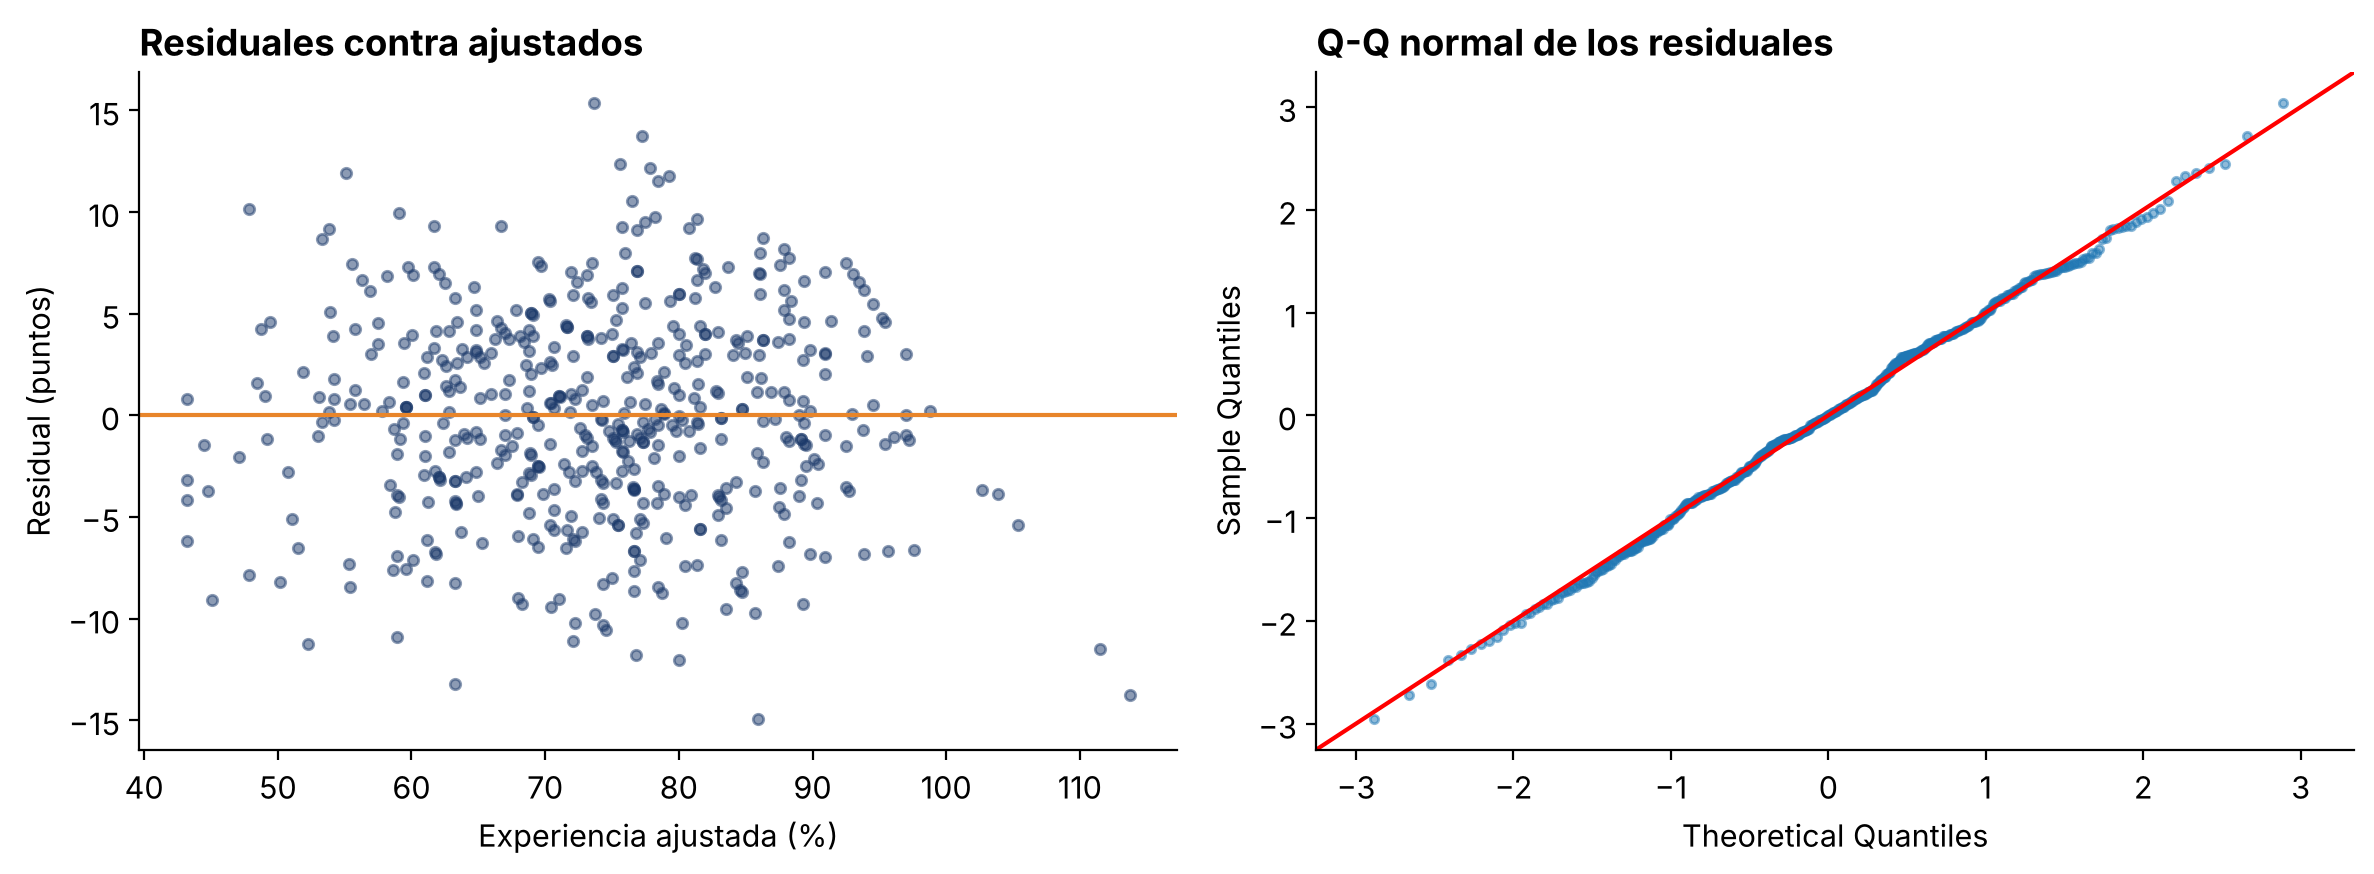

Señal con EE robusto HC3: coef = 1.563, IC 95 % [1.491, 1.635]


In [12]:
res, ajust = mco.resid, mco.fittedvalues
bp = het_breuschpagan(res, mco.model.exog)
sw = stats.shapiro(res)
X = pd.DataFrame(mco.model.exog, columns=mco.model.exog_names).drop(columns="Intercept")
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
print(f"Breusch-Pagan: LM = {bp[0]:.2f}, p = {bp[1]:.4f}")
print(f"Shapiro-Wilk:  W = {sw.statistic:.4f}, p = {sw.pvalue:.4f}")
print("VIF:"); print(vif.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(ajust, res, s=14, alpha=0.5, color=AZUL)
ax[0].axhline(0, color=NARANJA, lw=1.5)
ax[0].set(title="Residuales contra ajustados", xlabel="Experiencia ajustada (%)", ylabel="Residual (puntos)")
sm.qqplot(res, line="45", fit=True, ax=ax[1], markersize=3, alpha=0.5)
ax[1].set_title("Q-Q normal de los residuales")
plt.tight_layout(); plt.savefig(FIG / "fig01_diagnostico_mco.png", dpi=150); plt.show()

# Errores estándar robustos HC3 (por si hay heterocedasticidad)
mco_hc3 = smf.ols(FORMULA, data=entrena).fit(cov_type="HC3")
print("Señal con EE robusto HC3: coef = {:.3f}, IC 95 % [{:.3f}, {:.3f}]".format(
    mco_hc3.params["senal_dbm"], *mco_hc3.conf_int().loc["senal_dbm"]))

**Lectura:** Breusch-Pagan no rechaza homocedasticidad (p = 0.23); Shapiro-Wilk no rechaza normalidad de los residuales (p = 0.85); todos los VIF son menores a 1.7, sin multicolinealidad. Los supuestos se cumplen, así que los errores estándar y los IC del MCO son confiables. Los errores robustos HC3 dan prácticamente el mismo intervalo para la señal.

### Interpretación en unidades del problema

In [13]:
b_senal = mco.params["senal_dbm"]
ic = mco_hc3.conf_int().loc["senal_dbm"]
print(f"+1 dBm de señal -> {b_senal:+.2f} puntos de experiencia")
print(f"+10 dBm (p. ej. de -70 a -60 dBm) -> {10*b_senal:+.1f} puntos (IC 95 %: {10*ic[0]:+.1f} a {10*ic[1]:+.1f})")
for b in ["5 GHz", "6 GHz"]:
    k = f"C(banda)[T.{b}]"
    print(f"{b} vs 2.4 GHz, con la misma señal: {mco.params[k]:+.2f} puntos (p = {mco.pvalues[k]:.1e})")
pred_tr = mco.predict(prueba)
resultados.append(metricas("MCO (paramétrico)", y_te, pred_tr))

+1 dBm de señal -> +1.56 puntos de experiencia
+10 dBm (p. ej. de -70 a -60 dBm) -> +15.6 puntos (IC 95 %: +14.9 a +16.4)
5 GHz vs 2.4 GHz, con la misma señal: +8.36 puntos (p = 3.3e-39)
6 GHz vs 2.4 GHz, con la misma señal: +8.57 puntos (p = 3.4e-18)


- **Señal:** cada dBm adicional se asocia con 1.56 puntos más de experiencia. Llevar un equipo de −70 a −60 dBm la sube unos 15.6 puntos.
- **Banda:** con la misma señal, una sesión en 5 GHz tiene 8.4 puntos más que en 2.4 GHz (6 GHz: +8.6).
- **Piso y tipo de dispositivo:** no son significativos (p > 0.2) una vez que se controla la señal. El Piso 3 no tiene peor experiencia por estar en el Piso 3, sino porque ahí la señal es más débil.

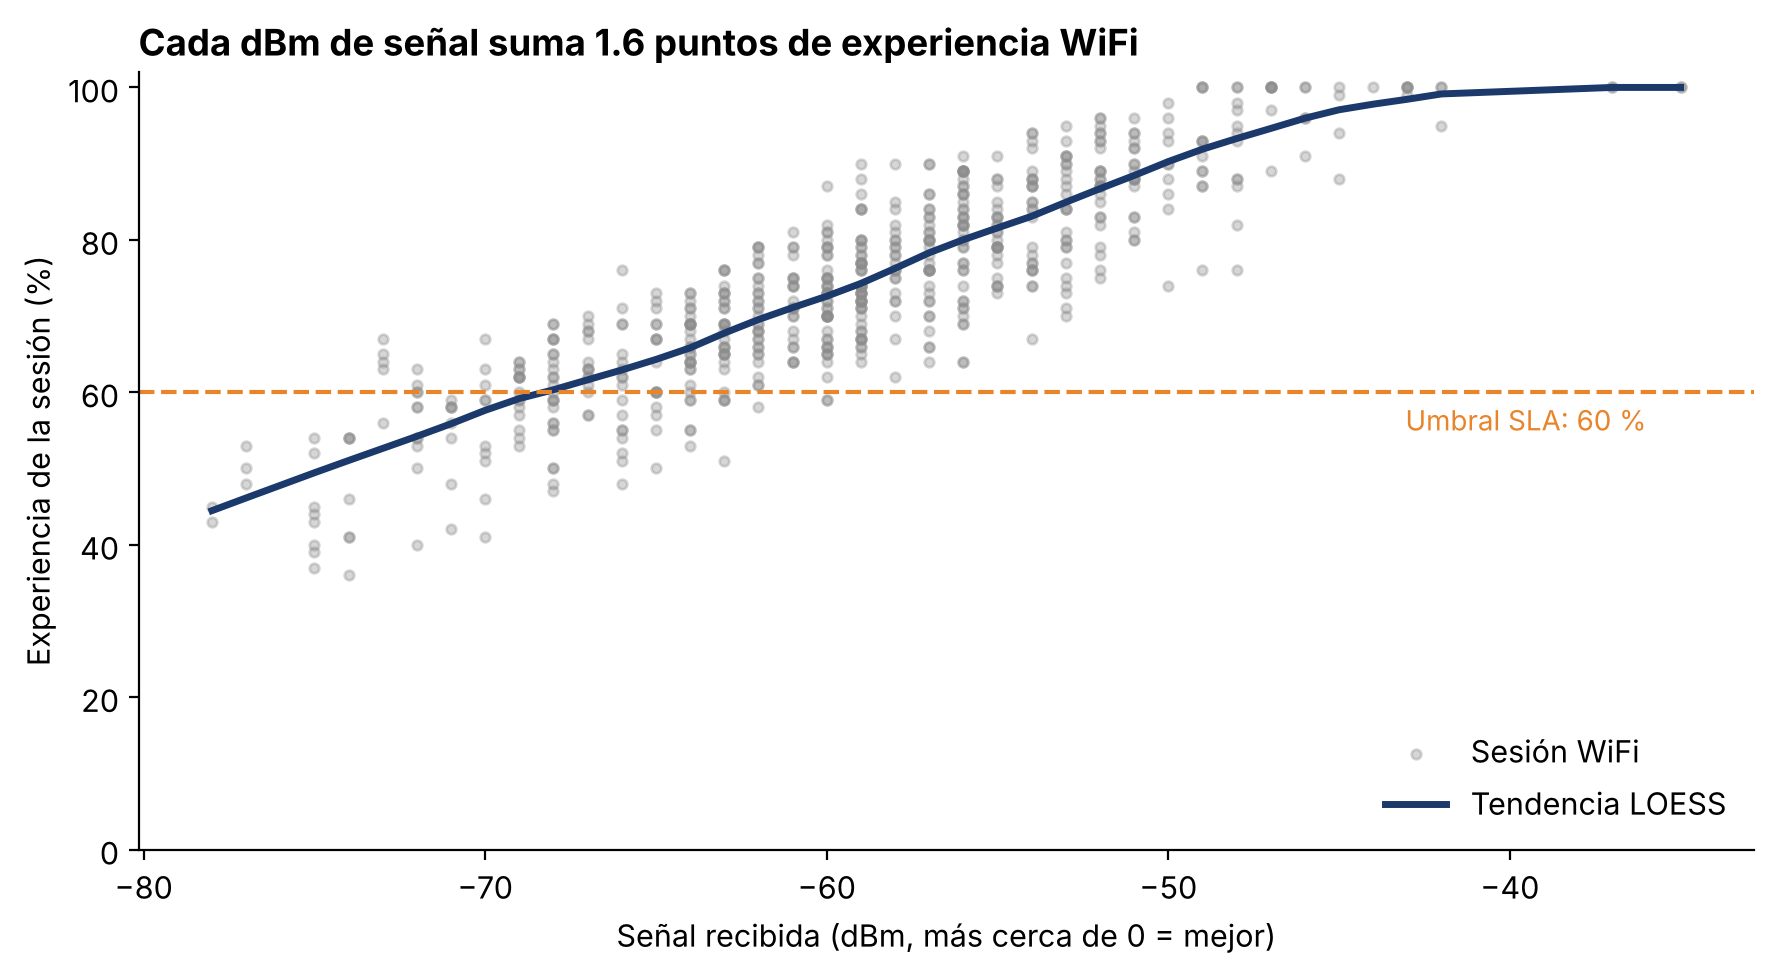

In [14]:
suave = lowess(wifi["experiencia"], wifi["senal_dbm"], frac=0.3)
fig, ax = plt.subplots()
ax.scatter(wifi["senal_dbm"], wifi["experiencia"], s=12, alpha=0.35, color=GRIS, label="Sesión WiFi")
ax.plot(suave[:, 0], np.clip(suave[:, 1], None, 100), color=AZUL, lw=2.5, label="Tendencia LOESS")
ax.axhline(60, color=NARANJA, ls="--", lw=1.5)
ax.text(-36, 55, "Umbral SLA: 60 %", color=NARANJA, fontsize=10, ha="right",
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set(title=f"Cada dBm de señal suma {b_senal:.1f} puntos de experiencia WiFi",
       xlabel="Señal recibida (dBm, más cerca de 0 = mejor)", ylabel="Experiencia de la sesión (%)", ylim=(0, 102))
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.savefig(FIG / "fig02_senal_experiencia.png", dpi=150); plt.show()

## 5. Regresión no paramétrica

**Árbol de regresión.** Profundidad y tamaño mínimo de hoja elegidos por validación cruzada de 10 pliegues.

Mejores hiperparámetros (CV 10 pliegues): {'arbol__max_depth': 5, 'arbol__min_samples_leaf': 5} | RMSE CV = 5.46
Hojas: 29


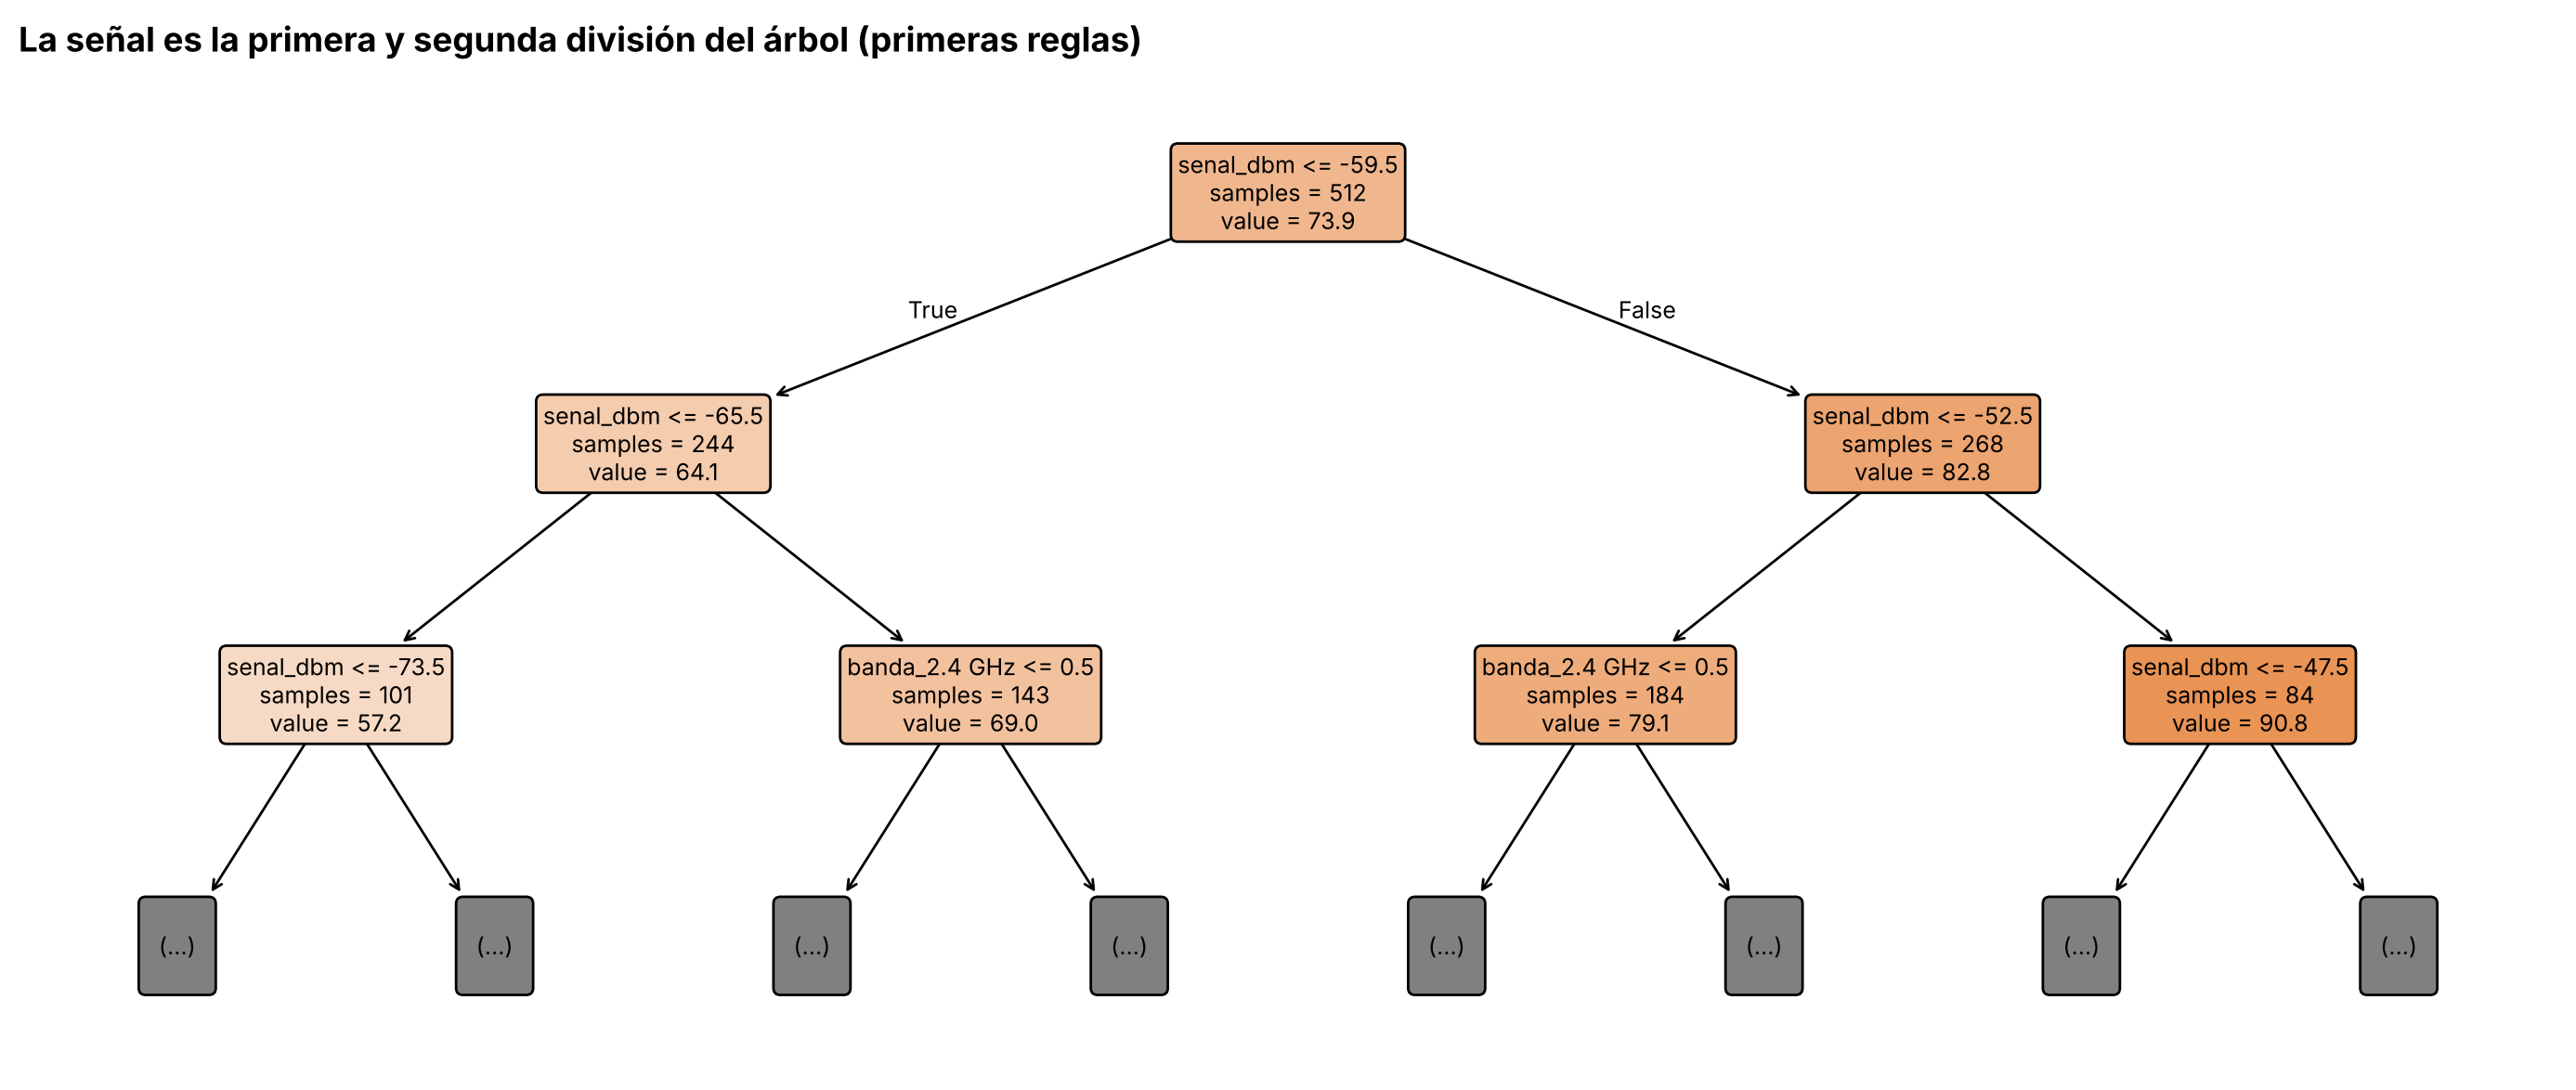

In [15]:
pre = ColumnTransformer([("num", "passthrough", NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
Xtr, Xte = entrena[NUM + CAT].astype({c: str for c in CAT}), prueba[NUM + CAT].astype({c: str for c in CAT})

arbol_cv = GridSearchCV(Pipeline([("pre", pre), ("arbol", DecisionTreeRegressor(random_state=SEMILLA))]),
                        {"arbol__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "arbol__min_samples_leaf": [5, 10, 20]},
                        cv=KFold(10, shuffle=True, random_state=SEMILLA), scoring="neg_root_mean_squared_error")
arbol_cv.fit(Xtr, y_tr)
mejor = arbol_cv.best_params_
arbol = arbol_cv.best_estimator_
print("Mejores hiperparámetros (CV 10 pliegues):", mejor, "| RMSE CV =", round(-arbol_cv.best_score_, 2))
print("Hojas:", arbol.named_steps["arbol"].get_n_leaves())
resultados.append(metricas(f"Árbol (prof.={mejor['arbol__max_depth']}, hoja≥{mejor['arbol__min_samples_leaf']})", y_te, arbol.predict(Xte)))

nombres_x = [n.replace("num__", "").replace("cat__", "") for n in arbol.named_steps["pre"].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arbol.named_steps["arbol"], max_depth=2, feature_names=nombres_x, filled=True, impurity=False,
          rounded=True, precision=1, fontsize=9, ax=ax)
ax.set_title("La señal es la primera y segunda división del árbol (primeras reglas)")
plt.tight_layout(); plt.savefig(FIG / "fig03_arbol.png", dpi=150); plt.show()

**k vecinos más cercanos.** Señal estandarizada y categorías en variables indicadoras; k elegido por validación cruzada de 5 pliegues.

k,3,5,7,10,15,20,30,50
RMSE validación,6.19,6.15,6.3,6.16,6.14,6.22,6.43,6.64


k elegido: 15


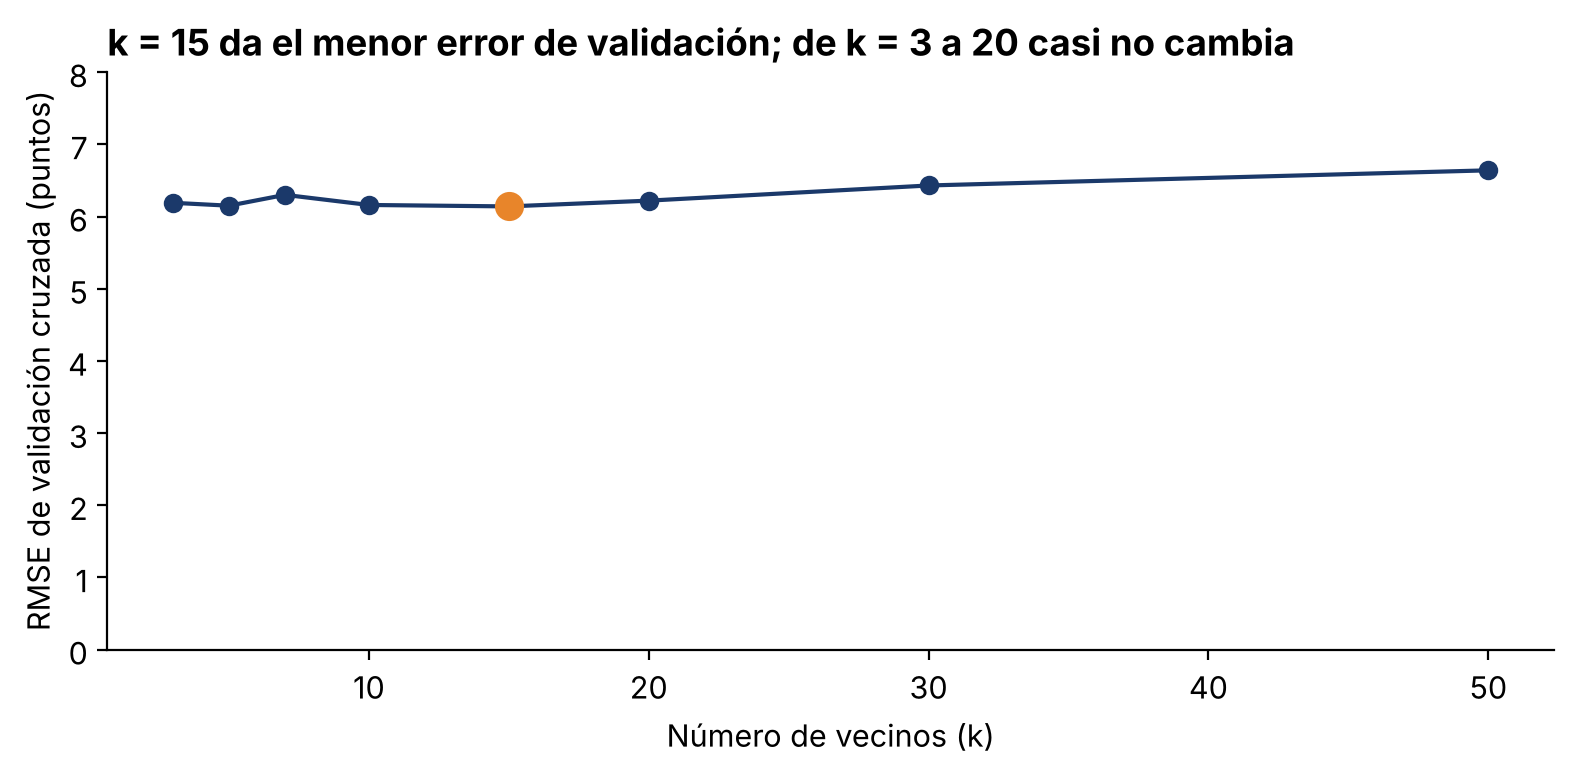

In [16]:
pre_knn = ColumnTransformer([("num", StandardScaler(), NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
ks = [3, 5, 7, 10, 15, 20, 30, 50]
knn_cv = GridSearchCV(Pipeline([("pre", pre_knn), ("knn", KNeighborsRegressor())]), {"knn__n_neighbors": ks},
                      cv=KFold(5, shuffle=True, random_state=SEMILLA), scoring="neg_root_mean_squared_error")
knn_cv.fit(Xtr, y_tr)
tabla_k = pd.DataFrame({"k": ks, "RMSE validación": -knn_cv.cv_results_["mean_test_score"]}).round(2)
display(tabla_k.set_index("k").T)
k_opt = knn_cv.best_params_["knn__n_neighbors"]
print("k elegido:", k_opt)
resultados.append(metricas(f"k-NN (k = {k_opt})", y_te, knn_cv.best_estimator_.predict(Xte)))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tabla_k["k"], tabla_k["RMSE validación"], marker="o", color=AZUL)
ax.scatter([k_opt], [tabla_k.set_index("k").loc[k_opt, "RMSE validación"]], color=NARANJA, s=90, zorder=3)
ax.set(title=f"k = {k_opt} da el menor error de validación; de k = 3 a 20 casi no cambia",
       xlabel="Número de vecinos (k)", ylabel="RMSE de validación cruzada (puntos)", ylim=(0, 8))
plt.tight_layout(); plt.savefig(FIG / "fig04_knn_validacion.png", dpi=150); plt.show()

## 6. Comparación de modelos

,Modelo,MAE,RMSE,R2
0,MCO (paramétrico),4.238,5.411,0.849
1,"Árbol (prof.=5, hoja≥5)",4.725,5.776,0.828
2,k-NN (k = 15),4.948,6.236,0.799
3,Referencia: media,11.223,13.925,-0.000


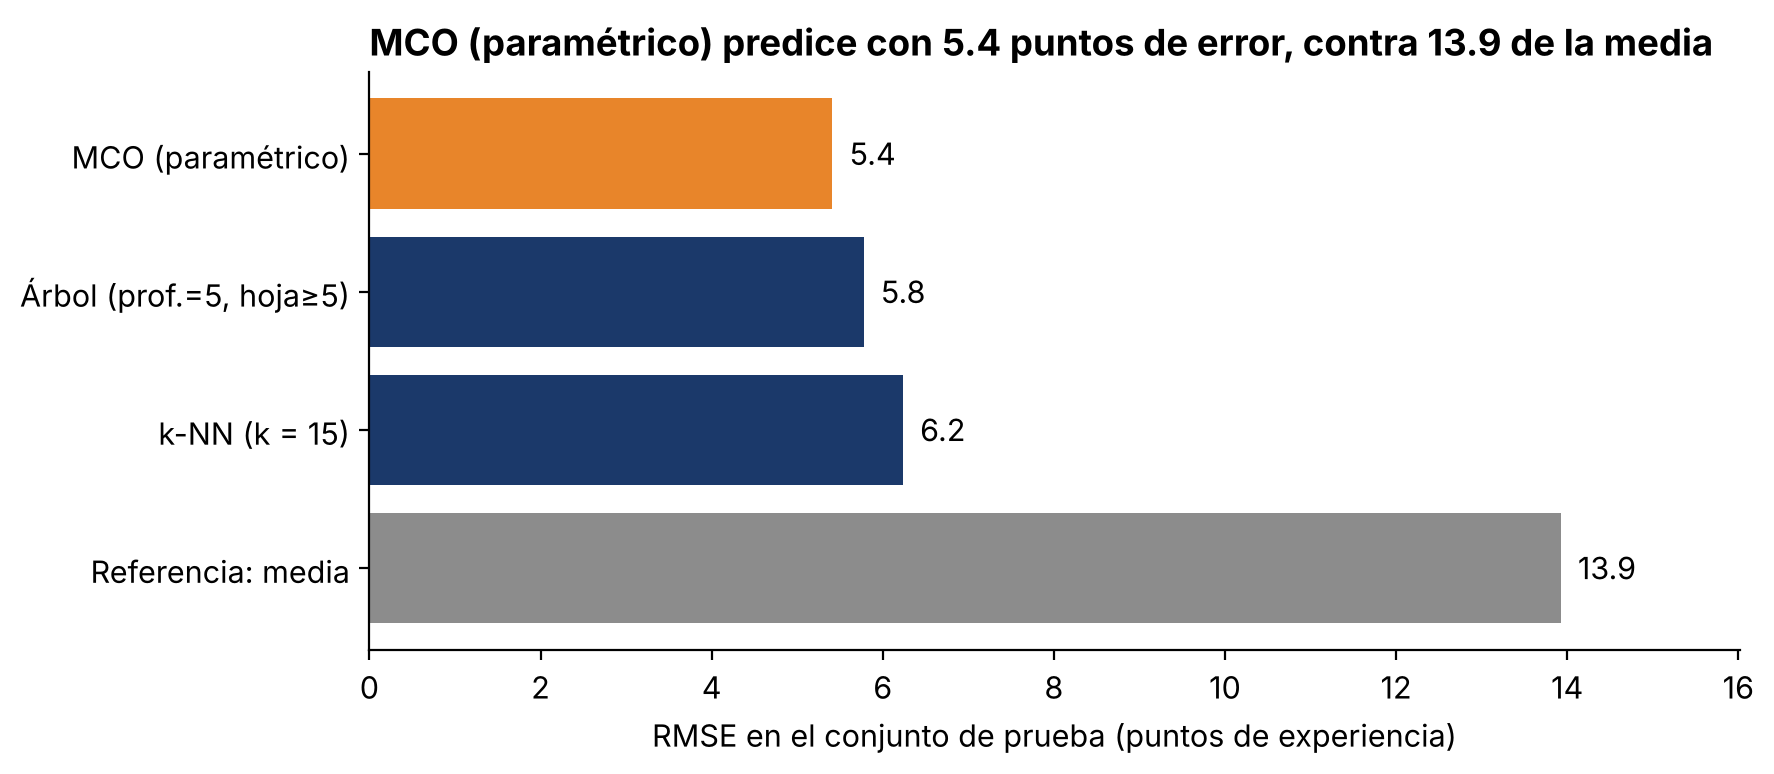

In [17]:
tabla = pd.DataFrame(resultados).sort_values("RMSE").reset_index(drop=True)
display(tabla.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
colores = [NARANJA if i == 0 else (GRIS if "Referencia" in m else AZUL) for i, m in enumerate(tabla["Modelo"])]
ax.barh(tabla["Modelo"], tabla["RMSE"], color=colores)
for i, v in enumerate(tabla["RMSE"]):
    ax.text(v + 0.2, i, f"{v:.1f}", va="center")
ax.invert_yaxis()
ax.set(title=f"{tabla.loc[0,'Modelo']} predice con {tabla.loc[0,'RMSE']:.1f} puntos de error, "
             f"contra {tabla['RMSE'].max():.1f} de la media",
       xlabel="RMSE en el conjunto de prueba (puntos de experiencia)", xlim=(0, tabla["RMSE"].max() * 1.15))
plt.tight_layout(); plt.savefig(FIG / "fig05_error_modelos.png", dpi=150); plt.show()

**Modelo elegido: MCO.** Tiene el menor error en prueba (MAE 4.2 y RMSE 5.4 puntos, R² = 0.85) y es el más fácil de explicar: su coeficiente de señal se traduce directamente en puntos de experiencia por dBm. El árbol y k-NN, que no suponen una forma lineal, llegan a un error parecido. Eso confirma que la relación es básicamente lineal.

**Escalabilidad.** La controladora UniFi puede registrar millones de sesiones. El MCO se puede estimar por bloques, sumando X'X y X'y sin cargar toda la tabla en memoria (abajo se comprueba que da los mismos coeficientes). También se puede agregar en MySQL antes de traer los datos a Python. Si el volumen crece aún más, el cálculo se mueve a Spark o Dask.

In [18]:
# Demostración de escalabilidad: MCO por bloques acumulando X'X y X'y (sin tener toda la tabla en memoria)
import patsy
y_full, X_full = patsy.dmatrices(FORMULA, entrena, return_type="dataframe")
XtX = np.zeros((X_full.shape[1],) * 2); Xty = np.zeros(X_full.shape[1])
for ini in range(0, len(X_full), 100):           # bloques de 100 filas
    Xb, yb = X_full.values[ini:ini + 100], y_full.values[ini:ini + 100, 0]
    XtX += Xb.T @ Xb; Xty += Xb.T @ yb
beta_bloques = np.linalg.solve(XtX, Xty)
print("Máxima diferencia contra statsmodels:", np.abs(beta_bloques - mco.params.values).max())

Máxima diferencia contra statsmodels: 8.810729923425242e-13


## 7. Visualización con buenas prácticas

,sesiones,pct_falla,senal
piso,,,
PB,212,5.7,-57.2
P2,118,11.0,-58.8
P1,268,15.7,-60.2
P3,42,50.0,-65.8


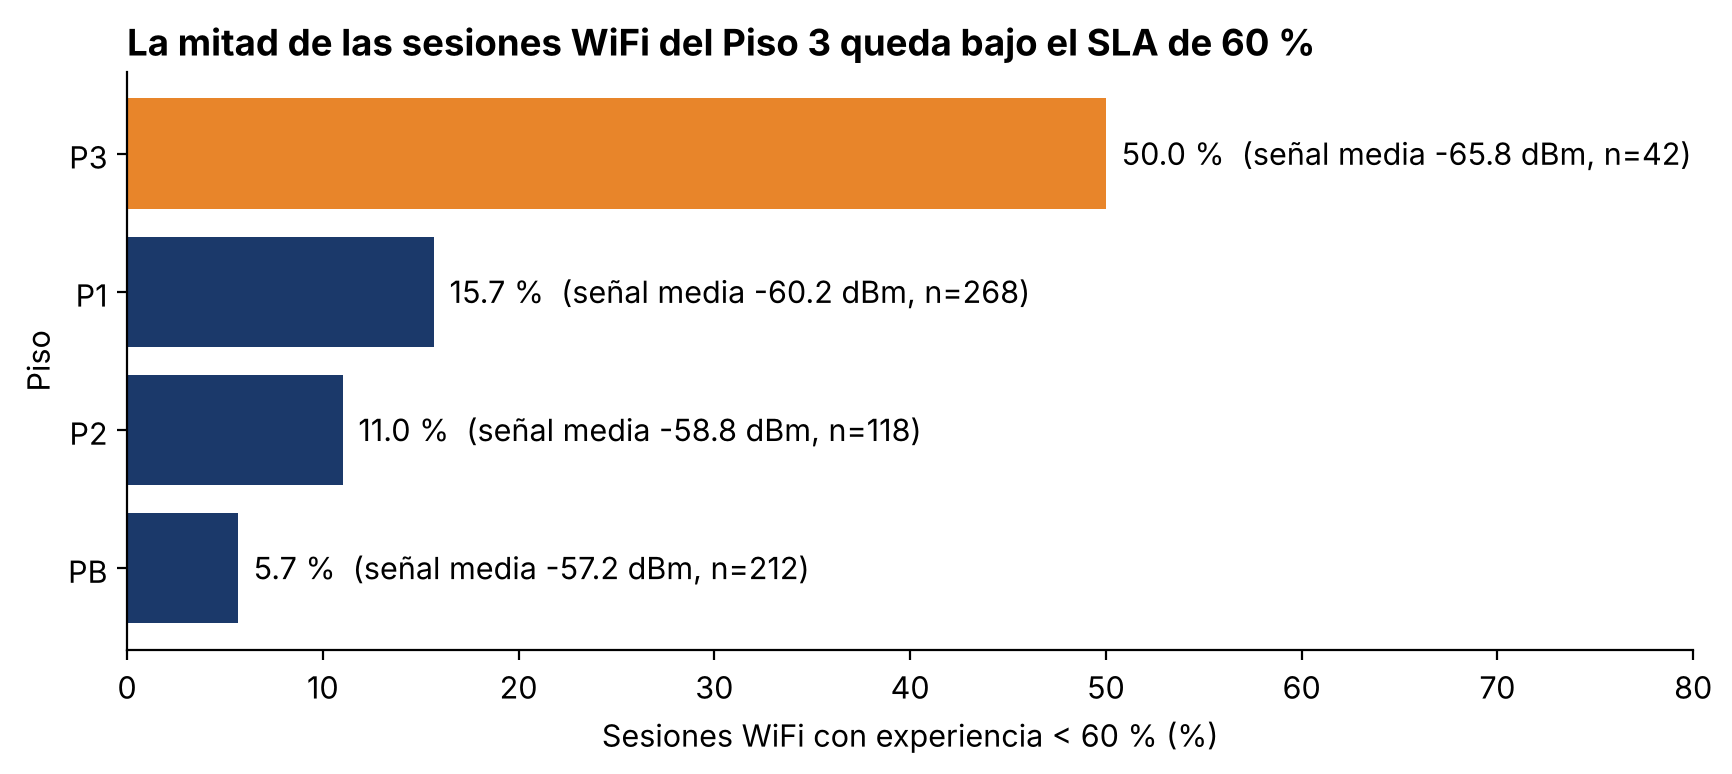

In [19]:
sla = (wifi.assign(falla=wifi["experiencia"] < 60)
           .groupby("piso", observed=True)
           .agg(sesiones=("falla", "size"), pct_falla=("falla", "mean"), senal=("senal_dbm", "mean")))
sla["pct_falla"] *= 100
sla = sla.sort_values("pct_falla")
display(sla.round(1))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(sla.index.astype(str), sla["pct_falla"], color=[NARANJA if p == "P3" else AZUL for p in sla.index])
for i, (p, r) in enumerate(sla.iterrows()):
    ax.text(r["pct_falla"] + 0.8, i, f"{r['pct_falla']:.1f} %  (señal media {r['senal']:.1f} dBm, n={int(r['sesiones'])})", va="center")
ax.set(title=f"La mitad de las sesiones WiFi del Piso 3 queda bajo el SLA de 60 %",
       xlabel="Sesiones WiFi con experiencia < 60 % (%)", ylabel="Piso", xlim=(0, 80))
plt.tight_layout(); plt.savefig(FIG / "fig06_sla_por_piso.png", dpi=150); plt.show()

Meta de señal (mediana fuera del P3): -59 dBm | señal media actual P3: -65.8 dBm
Experiencia media P3 predicha: actual 63.7 % -> escenario 75.9 %
Sigma residual del MCO: 5.11 puntos
Sesiones P3 bajo 60 % esperadas: actual 45.8 % -> escenario 1.3 %
Observado real hoy en P3: 50.0 % bajo 60 %


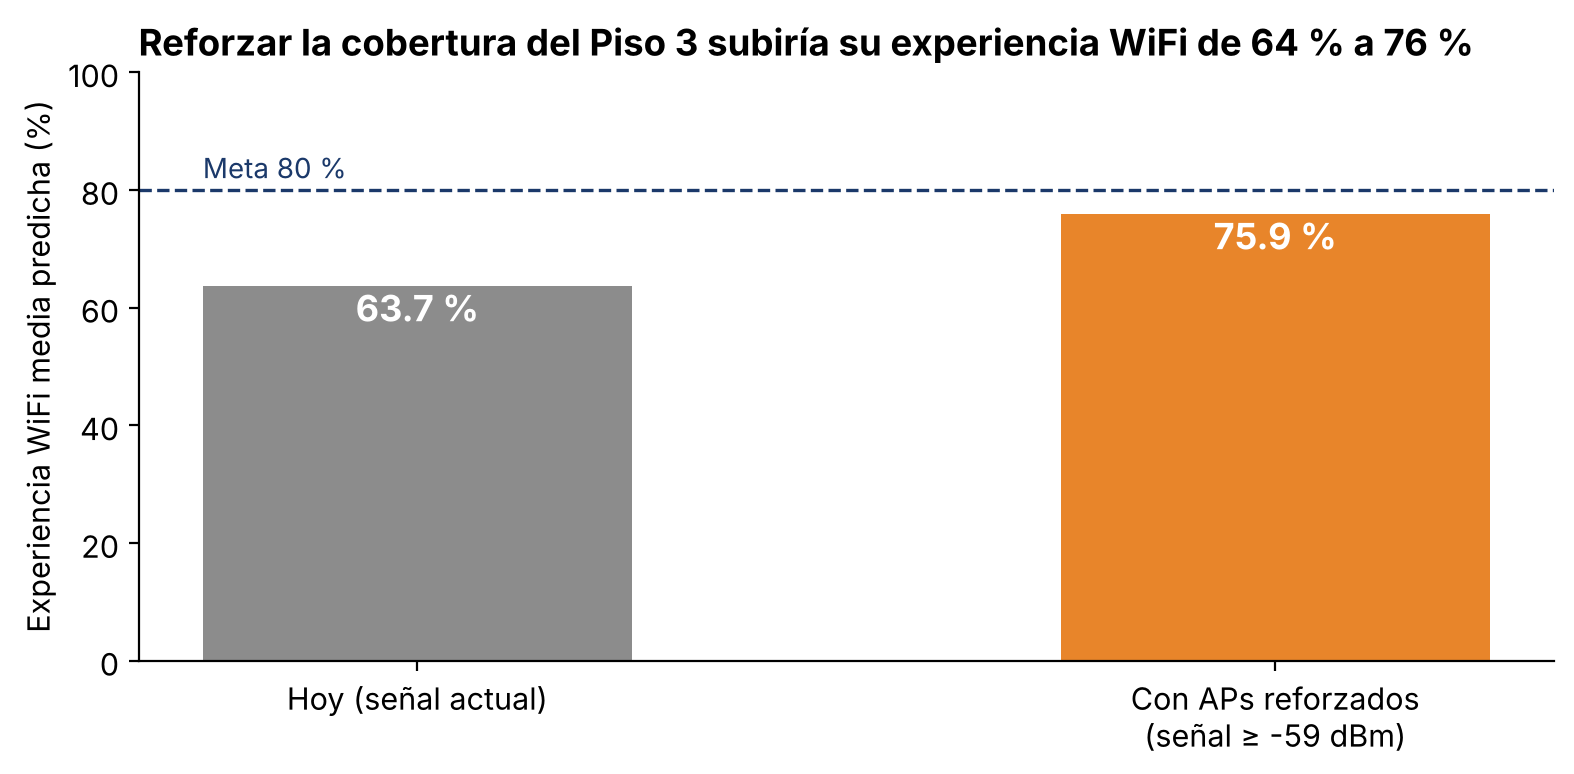

In [20]:
# Escenario: reforzar APs del Piso 3 para que su señal llegue a la mediana del resto del hospital
p3w = wifi[wifi["piso"] == "P3"].copy()
meta_senal = wifi.loc[wifi["piso"] != "P3", "senal_dbm"].median()
mejora = (meta_senal - p3w["senal_dbm"]).clip(lower=0)          # solo se sube la señal, nunca se baja
p3_esc = p3w.assign(senal_dbm=p3w["senal_dbm"] + mejora)
actual_pred, esc_pred = mco.predict(p3w), mco.predict(p3_esc).clip(upper=100)
print(f"Meta de señal (mediana fuera del P3): {meta_senal:.0f} dBm | señal media actual P3: {p3w['senal_dbm'].mean():.1f} dBm")
print(f"Experiencia media P3 predicha: actual {actual_pred.mean():.1f} % -> escenario {esc_pred.mean():.1f} %")
# Probabilidad de quedar bajo 60 % sumando el error del modelo (residual ~ Normal(0, sigma))
sigma = np.sqrt(mco.mse_resid)
p_bajo = lambda pred: stats.norm.cdf((60 - pred) / sigma).mean() * 100
print(f"Sigma residual del MCO: {sigma:.2f} puntos")
print(f"Sesiones P3 bajo 60 % esperadas: actual {p_bajo(actual_pred):.1f} % -> escenario {p_bajo(esc_pred):.1f} %")
print(f"Observado real hoy en P3: {(p3w['experiencia'] < 60).mean()*100:.1f} % bajo 60 %")

fig, ax = plt.subplots(figsize=(8, 4))
vals = [actual_pred.mean(), esc_pred.mean()]
ax.bar(["Hoy (señal actual)", f"Con APs reforzados\n(señal ≥ {meta_senal:.0f} dBm)"], vals, color=[GRIS, NARANJA], width=0.5)
for i, v in enumerate(vals):
    ax.text(i, v - 6, f"{v:.1f} %", ha="center", fontweight="bold", color="white", fontsize=13)
ax.axhline(80, color=AZUL, ls="--", lw=1.2); ax.text(-0.25, 82, "Meta 80 %", color=AZUL, fontsize=10)
ax.set(title=f"Reforzar la cobertura del Piso 3 subiría su experiencia WiFi de {vals[0]:.0f} % a {vals[1]:.0f} %",
       ylabel="Experiencia WiFi media predicha (%)", ylim=(0, 100))
plt.tight_layout(); plt.savefig(FIG / "fig08_escenario_p3.png", dpi=150); plt.show()

**Lectura del escenario:** si se refuerzan los APs del Piso 3 hasta la mediana de señal del resto del hospital (−59 dBm), el modelo predice que la experiencia WiFi media del piso sube unos 12 puntos. También baja mucho la proporción esperada de sesiones bajo el SLA. Es una extrapolación dentro del rango de señal observado (−78 a −35 dBm), no una medición.

### Antes y después

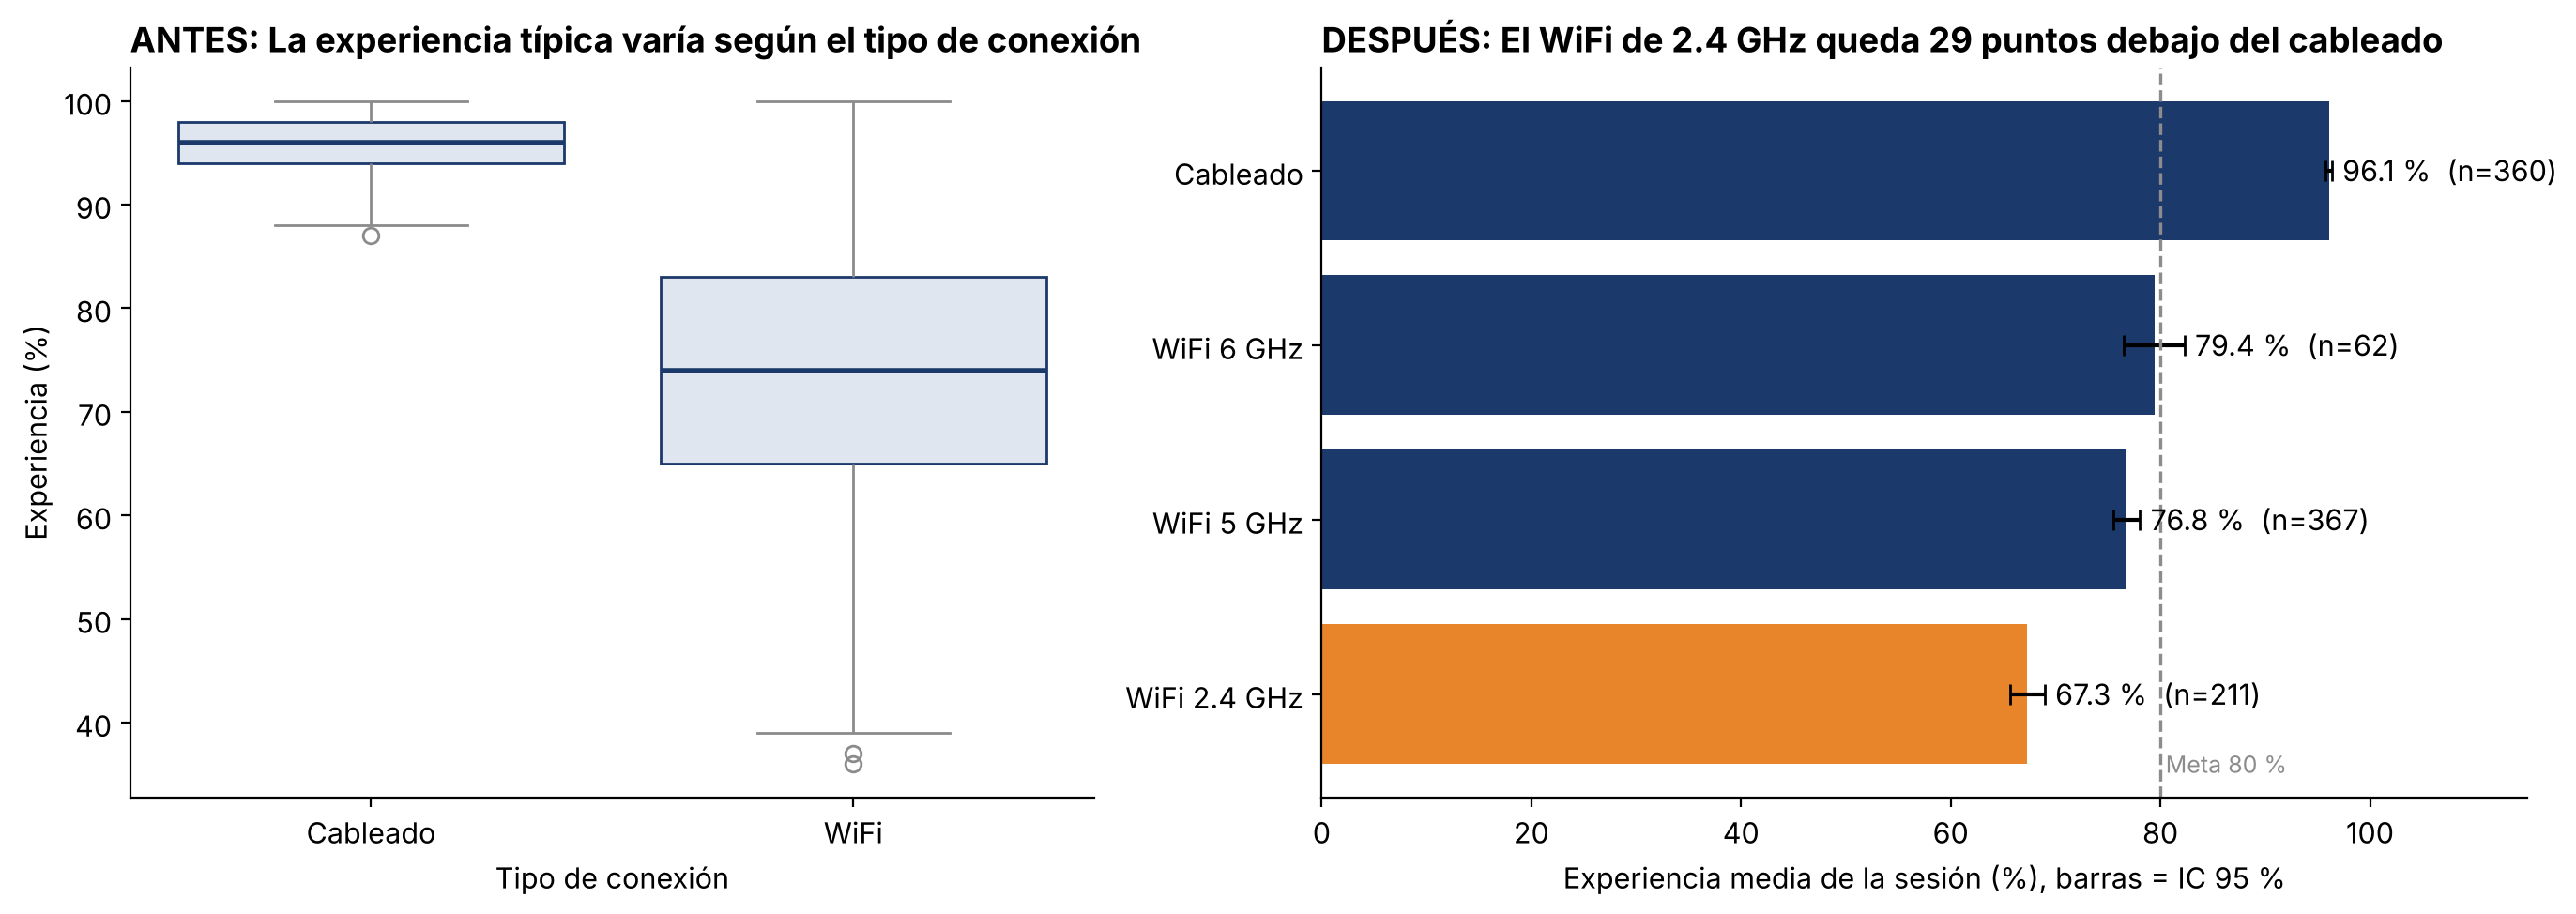

,mean,sem,size,ic
grupo,,,,
WiFi 2.4 GHz,67.30,0.85,211,1.67
WiFi 5 GHz,76.77,0.66,367,1.29
WiFi 6 GHz,79.42,1.44,62,2.88
Cableado,96.07,0.15,360,0.30


In [21]:
# ANTES: gráfica del Avance 1 (sección 5) tal como estaba
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.25]})
sns.boxplot(data=datos, x="conexion", y="experiencia", color=AZUL_SUAVE, ax=ax[0],
            boxprops=dict(edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2))
ax[0].set(title="ANTES: La experiencia típica varía según el tipo de conexión",
          xlabel="Tipo de conexión", ylabel="Experiencia (%)")
ax[0].title.set_fontsize(11)

# DESPUÉS: media con IC 95 % por medio físico y banda, ordenado, con meta
grupo = np.where(datos["conexion"] == "Cableado", "Cableado", "WiFi " + datos["banda"].fillna(""))
g = datos.assign(grupo=grupo).groupby("grupo")["experiencia"].agg(["mean", "sem", "size"])
g["ic"] = g["sem"] * stats.t.ppf(0.975, g["size"] - 1)
g = g.sort_values("mean")
colores = [NARANJA if i == g.index[0] else AZUL for i in g.index]
ax[1].barh(g.index, g["mean"], xerr=g["ic"], color=colores, capsize=4)
for i, (n, r) in enumerate(g.iterrows()):
    ax[1].text(r["mean"] + r["ic"] + 1, i, f"{r['mean']:.1f} %  (n={int(r['size'])})", va="center")
ax[1].axvline(80, color=GRIS, ls="--", lw=1.2); ax[1].text(80.5, -0.45, "Meta 80 %", color=GRIS, fontsize=9)
dif = g.loc["Cableado", "mean"] - g.loc["WiFi 2.4 GHz", "mean"]
ax[1].set(title=f"DESPUÉS: El WiFi de 2.4 GHz queda {dif:.0f} puntos debajo del cableado",
          xlabel="Experiencia media de la sesión (%), barras = IC 95 %", xlim=(0, 115))
ax[1].title.set_fontsize(11)
plt.tight_layout(); plt.savefig(FIG / "fig07_antes_despues.png", dpi=150); plt.show()
display(g.round(2))

## 8. Entorno

In [22]:
print("Semilla:", SEMILLA, "| pandas", pd.__version__, "| statsmodels", sm.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)
print("Figuras generadas:", sorted(p.name for p in FIG.glob("*.png")))

Semilla: 2026 | pandas 3.0.5 | statsmodels 0.15.0
scikit-learn 1.9.1
Figuras generadas: ['fig01_diagnostico_mco.png', 'fig02_senal_experiencia.png', 'fig03_arbol.png', 'fig04_knn_validacion.png', 'fig05_error_modelos.png', 'fig06_sla_por_piso.png', 'fig07_antes_despues.png', 'fig08_escenario_p3.png']


## Declaración de uso de inteligencia artificial
Se usó un asistente de IA (Claude, de Anthropic) para revisar la coherencia del notebook contra el dataset y para redactar el reporte del Avance 2. Todas las cifras se verificaron volviendo a ejecutar el notebook de principio a fin con la semilla 2026. El equipo puede explicar cualquier celda del notebook y cualquier sección del reporte.